### Importación y Carga de Datos Limpios

In [7]:
# Importación de librerías base
import pandas as pd
import numpy as np

# Cargar el dataset limpio que exportamos en la fase anterior
df = pd.read_csv('../data/processed/cell2cell_churn_clean.csv')

print(f"Dimensiones del dataset cargado: {df.shape}")
df.head()

Dimensiones del dataset cargado: (51047, 58)


,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,...,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000002,Yes,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,...,0,4,No,0,30,Yes,1-Highest,Suburban,Professional,No
1,3000010,Yes,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,...,0,5,No,0,30,No,4-Medium,Suburban,Professional,Yes
2,3000014,No,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,...,0,6,No,0,Unknown,No,3-Good,Town,Crafts,Yes
3,3000022,No,82.28,1312.0,75.0,1.24,0.0,0.0,157.0,8.1,...,0,6,No,0,10,No,4-Medium,Other,Other,No
4,3000026,Yes,17.14,0.0,17.0,0.00,0.0,0.0,0.0,-0.2,...,0,9,No,1,10,No,1-Highest,Other,Professional,Yes


### Identificar las variables categóricas

In [8]:
# 1. Transformar la variable objetivo 'Churn' a numérica (1 para Yes, 0 para No)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 2. Excluir columnas que no aportan al modelo (como ID y ServiceArea por alta cardinalidad)
columnas_a_excluir = ['CustomerID', 'ServiceArea']
for col in columnas_a_excluir:
    if col in df.columns:
        df = df.drop(columns=[col])

print("Columnas de identificación y alta cardinalidad excluidas.")

# 3. Identificar las variables categóricas restantes
columnas_categoricas = df.select_dtypes(include=['object', 'str']).columns.tolist()

print(f"Aplicando One-Hot Encoding a {len(columnas_categoricas)} variables categóricas...")

# 4. Aplicar One-Hot Encoding (drop_first=True evita la multicolinealidad)
df_codificado = pd.get_dummies(df, columns=columnas_categoricas, drop_first=True)

print(f"Dimensiones finales del dataset codificado: {df_codificado.shape}")
df_codificado.head()

Columnas de identificación y alta cardinalidad excluidas.
Aplicando One-Hot Encoding a 21 variables categóricas...
Dimensiones finales del dataset codificado: (51047, 84)


,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,...,PrizmCode_Town,Occupation_Crafts,Occupation_Homemaker,Occupation_Other,Occupation_Professional,Occupation_Retired,Occupation_Self,Occupation_Student,MaritalStatus_Unknown,MaritalStatus_Yes
0,1,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,0.7,...,False,False,False,False,True,False,False,False,False,False
1,1,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,0.3,...,False,False,False,False,True,False,False,False,False,True
2,0,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,0.0,...,True,True,False,False,False,False,False,False,False,True
3,0,82.28,1312.0,75.0,1.24,0.0,0.0,157.0,8.1,52.0,...,False,False,False,True,False,False,False,False,False,False
4,1,17.14,0.0,17.0,0.00,0.0,0.0,0.0,-0.2,0.0,...,False,False,False,False,True,False,False,False,False,True


### Codificación de Variables Categóricas (Encoding)

In [9]:
# 1. Transformar la variable objetivo 'Churn' a numérica (1 para Yes, 0 para No)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print("Variable objetivo 'Churn' convertida a numérica (1/0).")

# 2. Identificar las variables categóricas restantes (excluyendo CustomerID si lo tienes)
columnas_categoricas = df.select_dtypes(include=['object', 'str']).columns.tolist()

if 'CustomerID' in columnas_categoricas:
    columnas_categoricas.remove('CustomerID')

print(f"Aplicando One-Hot Encoding a {len(columnas_categoricas)} variables categóricas...")

# 3. Aplicar One-Hot Encoding con Pandas (drop_first=True evita la multicolinealidad)
df_codificado = pd.get_dummies(df, columns=columnas_categoricas, drop_first=True)

print(f"Dimensiones del dataset antes del encoding: {df.shape}")
print(f"Dimensiones del dataset después del encoding: {df_codificado.shape}")

# Vista previa de las nuevas columnas generadas
df_codificado.head()

Variable objetivo 'Churn' convertida a numérica (1/0).
Aplicando One-Hot Encoding a 21 variables categóricas...
Dimensiones del dataset antes del encoding: (51047, 56)
Dimensiones del dataset después del encoding: (51047, 84)


,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,...,PrizmCode_Town,Occupation_Crafts,Occupation_Homemaker,Occupation_Other,Occupation_Professional,Occupation_Retired,Occupation_Self,Occupation_Student,MaritalStatus_Unknown,MaritalStatus_Yes
0,NaN,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,0.7,...,False,False,False,False,True,False,False,False,False,False
1,NaN,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,0.3,...,False,False,False,False,True,False,False,False,False,True
2,NaN,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,0.0,...,True,True,False,False,False,False,False,False,False,True
3,NaN,82.28,1312.0,75.0,1.24,0.0,0.0,157.0,8.1,52.0,...,False,False,False,True,False,False,False,False,False,False
4,NaN,17.14,0.0,17.0,0.00,0.0,0.0,0.0,-0.2,0.0,...,False,False,False,False,True,False,False,False,False,True


### División en Entrenamiento y Prueba (Train/Test Split)

In [12]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Cargar el archivo RAW correcto con su nombre real
df_original = pd.read_csv('../data/raw/cell2celltrain.csv')
print(f"Dimensiones del archivo RAW: {df_original.shape}")

# 2. Asegurarnos de tener la columna Churn original en nuestro DataFrame principal
df['Churn'] = df_original['Churn'].values

# 3. Transformación robusta de la variable objetivo
df['Churn'] = (
    df['Churn']
    .astype(str)
    .str.strip()
    .str.capitalize()
    .map({'Yes': 1, 'No': 0})
)

print("\nConteo de Churn tras el mapeo:")
print(df['Churn'].value_counts(dropna=False))

# 4. Excluir identificadores y alta cardinalidad (CustomerID y ServiceArea)
columnas_a_excluir = ['CustomerID', 'ServiceArea']
for col in columnas_a_excluir:
    if col in df.columns:
        df = df.drop(columns=[col])

# 5. Aplicar One-Hot Encoding a las variables categóricas restantes
columnas_categoricas = df.select_dtypes(include=['object', 'str']).columns.tolist()
print(f"\nAplicando One-Hot Encoding a {len(columnas_categoricas)} variables categóricas...")

df_codificado = pd.get_dummies(df.dropna(subset=['Churn']), drop_first=True)
print(f"Dimensiones finales del dataset codificado: {df_codificado.shape}")

# 6. División estratificada (80% entrenamiento, 20% prueba)
X = df_codificado.drop(columns=['Churn'])
y = df_codificado['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print(f"\n¡Listo! Datos divididos con éxito:")
print(f"X_entrenamiento shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

Dimensiones del archivo RAW: (51047, 58)

Conteo de Churn tras el mapeo:
Churn
0    36336
1    14711
Name: count, dtype: int64

Aplicando One-Hot Encoding a 21 variables categóricas...
Dimensiones finales del dataset codificado: (51047, 84)

¡Listo! Datos divididos con éxito:
X_entrenamiento shape: (40837, 83)
X_test shape: (10210, 83)


### Modelado y Entrenamiento: Baseline (Regresión Logística)

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score

# 1. Crear un Pipeline que escale los datos y entrene una Regresión Logística
# El escalado es fundamental para que las variables numéricas tengan el mismo peso
baseline_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=1000, random_state=42))
])

print("Entrenando el modelo de línea base (Regresión Logística)...")
baseline_pipeline.fit(X_train, y_train)

# 2. Generar predicciones sobre el conjunto de prueba
y_pred = baseline_pipeline.predict(X_test)
y_prob = baseline_pipeline.predict_proba(X_test)[:, 1]

# 3. Evaluar el rendimiento
print("\n--- Reporte de Clasificación (Baseline) ---")
print(classification_report(y_test, y_pred))

print(f"ROC-AUC Score en Test: {roc_auc_score(y_test, y_prob):.4f}")

Entrenando el modelo de línea base (Regresión Logística)...

--- Reporte de Clasificación (Baseline) ---
              precision    recall  f1-score   support

           0       0.72      0.98      0.83      7268
           1       0.49      0.04      0.07      2942

    accuracy                           0.71     10210
   macro avg       0.60      0.51      0.45     10210
weighted avg       0.65      0.71      0.61     10210

ROC-AUC Score en Test: 0.6162


### Regresión Logística con Balanceo de Clases

In [14]:
# 1. Creamos el pipeline pero activando el balanceo de clases
pipeline_balanceado = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(
        max_iter=1000, 
        random_state=42, 
        class_weight='balanced'
    ))
])

print("Entrenando Regresión Logística con class_weight='balanced'...")
pipeline_balanceado.fit(X_train, y_train)

# 2. Predicciones
y_pred_balanced = pipeline_balanceado.predict(X_test)
y_prob_balanced = pipeline_balanceado.predict_proba(X_test)[:, 1]

# 3. Evaluación
print("\n--- Reporte de Clasificación (Modelo Balanceado) ---")
print(classification_report(y_test, y_pred_balanced))

print(f"ROC-AUC Score en Test: {roc_auc_score(y_test, y_prob_balanced):.4f}")

Entrenando Regresión Logística con class_weight='balanced'...

--- Reporte de Clasificación (Modelo Balanceado) ---
              precision    recall  f1-score   support

           0       0.78      0.59      0.67      7268
           1       0.36      0.58      0.45      2942

    accuracy                           0.59     10210
   macro avg       0.57      0.59      0.56     10210
weighted avg       0.66      0.59      0.60     10210

ROC-AUC Score en Test: 0.6165


### Modelado Avanzado: Random Forest

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# 1. Instanciar Random Forest optimizado para datos tabulares y desbalanceados
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,         # Limitamos un poco la profundidad para evitar sobreajuste (overfitting)
    random_state=42,
    class_weight='balanced',
    n_jobs=-1             # Utiliza todos los núcleos disponibles de tu procesador
)

print("Entrenando Random Forest...")
rf_model.fit(X_train, y_train)

# 2. Generar predicciones
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# 3. Evaluar el rendimiento
print("\n--- Reporte de Clasificación (Random Forest) ---")
print(classification_report(y_test, y_pred_rf))

print(f"ROC-AUC Score en Test: {roc_auc_score(y_test, y_prob_rf):.4f}")

Entrenando Random Forest...

--- Reporte de Clasificación (Random Forest) ---
              precision    recall  f1-score   support

           0       0.79      0.61      0.69      7268
           1       0.39      0.61      0.47      2942

    accuracy                           0.61     10210
   macro avg       0.59      0.61      0.58     10210
weighted avg       0.68      0.61      0.63     10210

ROC-AUC Score en Test: 0.6591


### Interpretación del Modelo y Feature Importance

--- Top 15 Variables que más influyen en el Churn ---
                 Feature  Importance
0   CurrentEquipmentDays    0.109594
1        MonthsInService    0.093772
2      PercChangeMinutes    0.053576
3         MonthlyMinutes    0.049547
4     PercChangeRevenues    0.038136
5   TotalRecurringCharge    0.037328
6         MonthlyRevenue    0.037019
7      OffPeakCallsInOut    0.031327
8         PeakCallsInOut    0.030235
9          ReceivedCalls    0.028070
10        OverageMinutes    0.027618
11       UnansweredCalls    0.027519
12         OutboundCalls    0.025427
13   DroppedBlockedCalls    0.024870
14                AgeHH1    0.024454


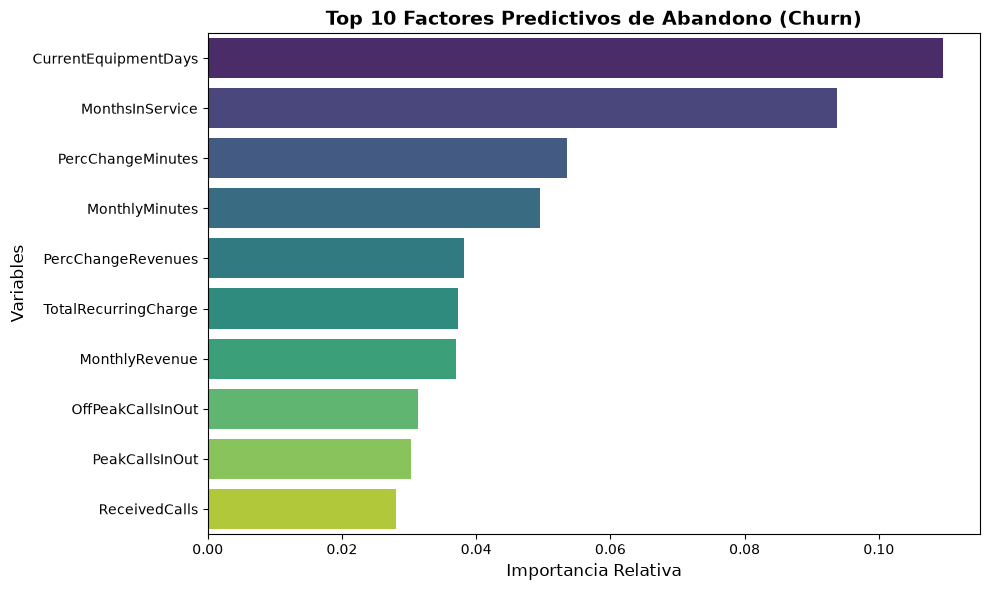

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Obtener la importancia de las variables del Random Forest
importances = rf_model.feature_importances_
feature_names = X_train.columns

# 2. Crear un DataFrame ordenado
df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

# 3. Mostrar las 15 variables más importantes
print("--- Top 15 Variables que más influyen en el Churn ---")
print(df_importance.head(15))

# 4. Graficar el Top 10 para tu reporte o presentación
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance', 
    y='Feature', 
    data=df_importance.head(10), 
    palette='viridis',
    hue='Feature',
    legend=False
)
plt.title('Top 10 Factores Predictivos de Abandono (Churn)', fontsize=14, fontweight='bold')
plt.xlabel('Importancia Relativa', fontsize=12)
plt.ylabel('Variables', fontsize=12)
plt.tight_layout()
plt.show()

In [17]:
import os
import joblib
from sklearn.ensemble import RandomForestClassifier

# 1. Asegúrate de definir y entrenar tu modelo primero:
# (Reemplaza X_train e y_train con tus variables de entrenamiento reales)
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# 2. '..' sube un nivel (sales de la carpeta notebooks/) y entra en models/
models_dir = os.path.abspath(os.path.join('..', 'models'))
os.makedirs(models_dir, exist_ok=True)

# 3. Guardar el modelo
model_filename = os.path.join(models_dir, 'modelo_churn_random_forest.pkl')
joblib.dump(rf_model, model_filename)

print(f"¡Modelo guardado exitosamente en: {model_filename}")

¡Modelo guardado exitosamente en: /Users/rodensrosier/Downloads/abandono-de-clientes-sector-telecomunicaciones/models/modelo_churn_random_forest.pkl
